# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

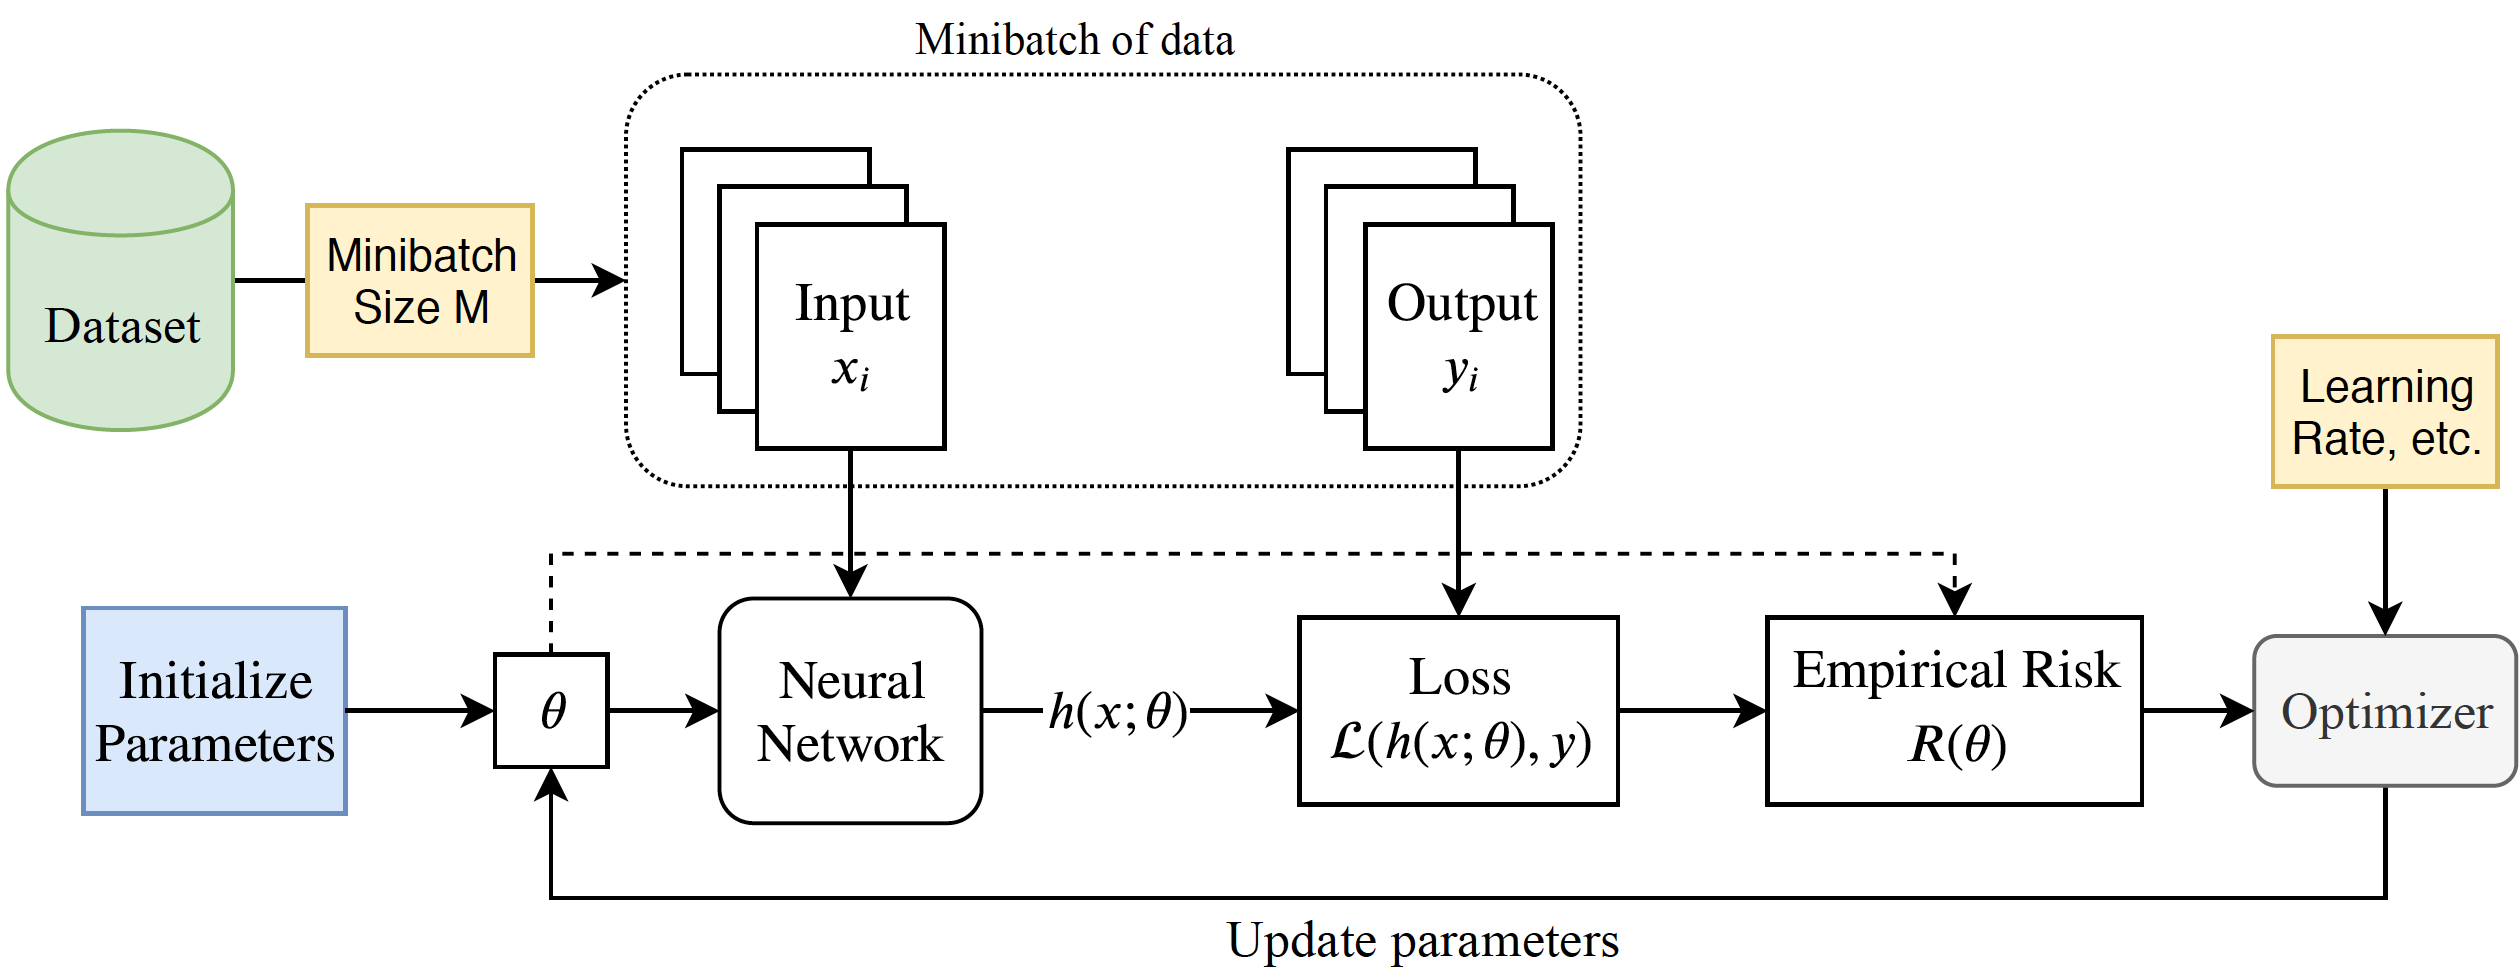

## 0 · Setup

In [2]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.8.0 | device: cpu


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


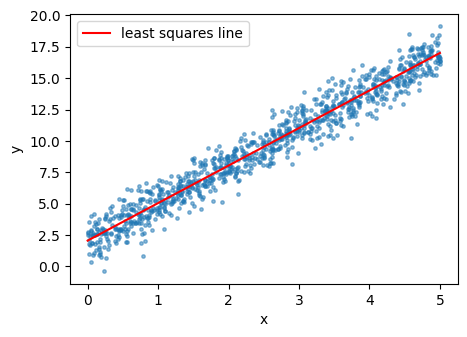

In [3]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen) # value x between 0 and 5
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen) # the equation plus noise

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist() # least squares solution
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item() # loss function 
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [4]:
def full_loss(model):
    with torch.no_grad(): # compute the loss on the full dataset, without gradient tracking
        return ((model(x_toy) - y_toy) ** 2).mean().item() # mean square error (MSE)

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 1 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [5]:
hist_sgd = train_toy(batch_size=1)

epoch  1 | J = 1.0230 | w = 2.891, b = 2.075
epoch  2 | J = 0.9702 | w = 3.026, b = 2.103
epoch  3 | J = 0.9785 | w = 3.060, b = 2.020
epoch  4 | J = 1.0928 | w = 3.165, b = 1.898
epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch  6 | J = 0.9735 | w = 3.021, b = 2.131
epoch  7 | J = 1.0184 | w = 2.892, b = 2.084
epoch  8 | J = 0.9566 | w = 3.013, b = 2.081
epoch  9 | J = 1.0841 | w = 2.855, b = 2.087
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 11 | J = 1.0366 | w = 3.056, b = 2.174
epoch 12 | J = 1.0330 | w = 3.068, b = 2.130
epoch 13 | J = 1.0759 | w = 3.090, b = 2.132
epoch 14 | J = 1.0242 | w = 2.915, b = 1.997
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 16 | J = 1.3911 | w = 2.786, b = 1.976
epoch 17 | J = 1.0375 | w = 2.872, b = 2.112
epoch 18 | J = 0.9864 | w = 3.090, b = 1.933
epoch 19 | J = 0.9582 | w = 3.017, b = 2.076
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 1.18 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [6]:
hist_mb = train_toy(batch_size=32)

epoch  1 | J = 8.3765 | w = 1.290, b = 7.434
epoch  2 | J = 6.4393 | w = 1.595, b = 6.707
epoch  3 | J = 4.9947 | w = 1.744, b = 6.033
epoch  4 | J = 3.9405 | w = 1.904, b = 5.466
epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch  6 | J = 2.5936 | w = 2.240, b = 4.604
epoch  7 | J = 2.1565 | w = 2.310, b = 4.232
epoch  8 | J = 1.8781 | w = 2.474, b = 3.953
epoch  9 | J = 1.6184 | w = 2.477, b = 3.674
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 11 | J = 1.3177 | w = 2.637, b = 3.265
epoch 12 | J = 1.2207 | w = 2.670, b = 3.093
epoch 13 | J = 1.1542 | w = 2.734, b = 2.958
epoch 14 | J = 1.1020 | w = 2.739, b = 2.826
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 16 | J = 1.0336 | w = 2.810, b = 2.636
epoch 17 | J = 1.0126 | w = 2.829, b = 2.556
epoch 18 | J = 0.9964 | w = 2.867, b = 2.491
epoch 19 | J = 0.9886 | w = 2.900, b = 2.435
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.05 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [7]:
hist_mom = train_toy(batch_size=64, momentum=0.9)

epoch  1 | J = 6.1264 | w = 1.434, b = 5.922
epoch  2 | J = 1.4561 | w = 2.634, b = 3.438
epoch  3 | J = 1.0152 | w = 3.024, b = 2.225
epoch  4 | J = 0.9865 | w = 3.092, b = 1.923
epoch  5 | J = 0.9673 | w = 3.071, b = 1.918
epoch  6 | J = 0.9700 | w = 3.055, b = 2.005
epoch  7 | J = 0.9650 | w = 3.032, b = 2.063
epoch  8 | J = 1.0744 | w = 3.099, b = 2.102
epoch  9 | J = 0.9555 | w = 3.013, b = 2.073
epoch 10 | J = 0.9531 | w = 2.964, b = 2.075
epoch 11 | J = 0.9698 | w = 2.941, b = 2.056
epoch 12 | J = 0.9842 | w = 2.928, b = 2.052
epoch 13 | J = 0.9596 | w = 2.954, b = 2.062
epoch 14 | J = 0.9543 | w = 3.008, b = 2.081
epoch 15 | J = 0.9756 | w = 3.041, b = 2.074
epoch 16 | J = 0.9545 | w = 3.009, b = 2.079
epoch 17 | J = 0.9496 | w = 2.985, b = 2.056
epoch 18 | J = 0.9775 | w = 3.036, b = 2.098
epoch 19 | J = 0.9519 | w = 3.004, b = 2.070
epoch 20 | J = 0.9505 | w = 3.005, b = 2.048
updates: 320 | training time: 0.03 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

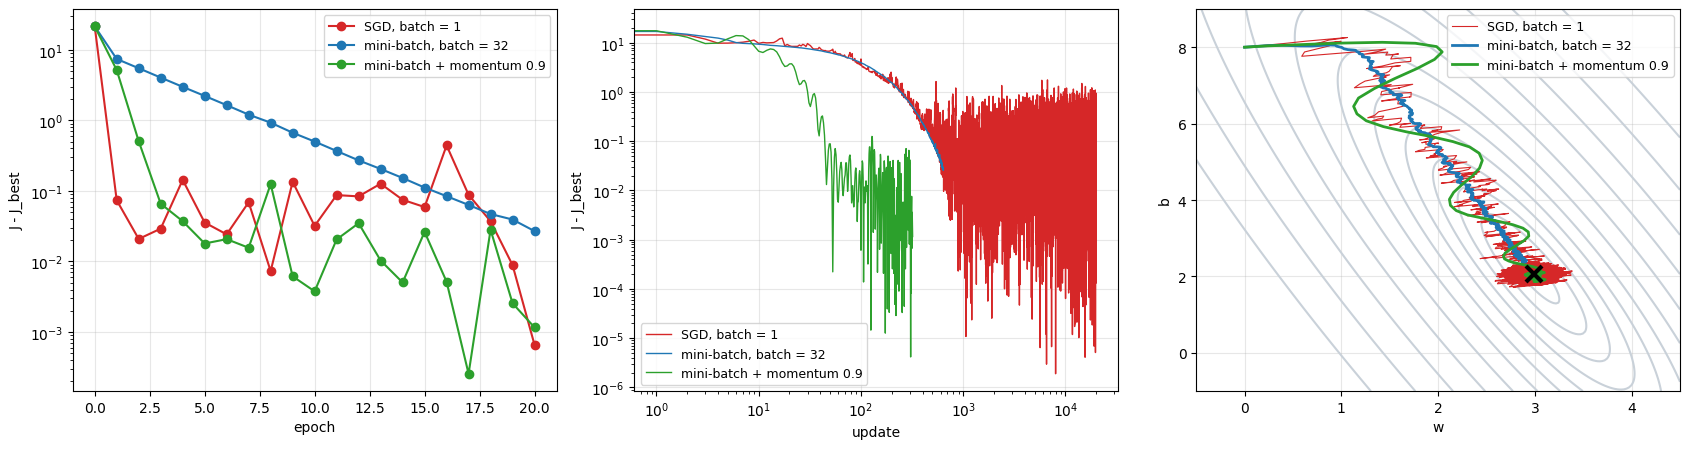

SGD, batch = 1               updates:  20000 | time: 1.18 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.05 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    320 | time: 0.03 s | final J - J_best: 0.0012


In [8]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

train (54000, 784) | val (6000, 784) | test (10000, 784)


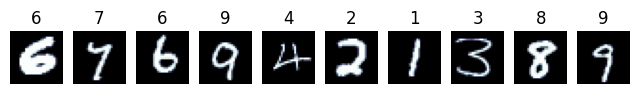

In [9]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [10]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [11]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.2744 | val loss 0.1607 | val acc 95.10% | 0.6 s
epoch  2 | lr 1.00e-03 | train loss 0.1179 | val loss 0.1233 | val acc 96.32% | 1.2 s
epoch  3 | lr 1.00e-03 | train loss 0.0836 | val loss 0.0973 | val acc 97.05% | 1.7 s
epoch  4 | lr 1.00e-03 | train loss 0.0614 | val loss 0.0815 | val acc 97.42% | 2.2 s
epoch  5 | lr 1.00e-03 | train loss 0.0522 | val loss 0.0857 | val acc 97.22% | 2.8 s
epoch  6 | lr 1.00e-03 | train loss 0.0420 | val loss 0.0939 | val acc 97.37% | 3.3 s
epoch  7 | lr 1.00e-03 | train loss 0.0345 | val loss 0.0989 | val acc 97.33% | 3.7 s
epoch  8 | lr 1.00e-03 | train loss 0.0302 | val loss 0.0964 | val acc 97.55% | 4.2 s
epoch  9 | lr 1.00e-03 | train loss 0.0255 | val loss 0.1036 | val acc 97.57% | 4.6 s
epoch 10 | lr 1.00e-03 | train loss 0.0229 | val loss 0.1142 | val acc 97.30% | 5.2 s


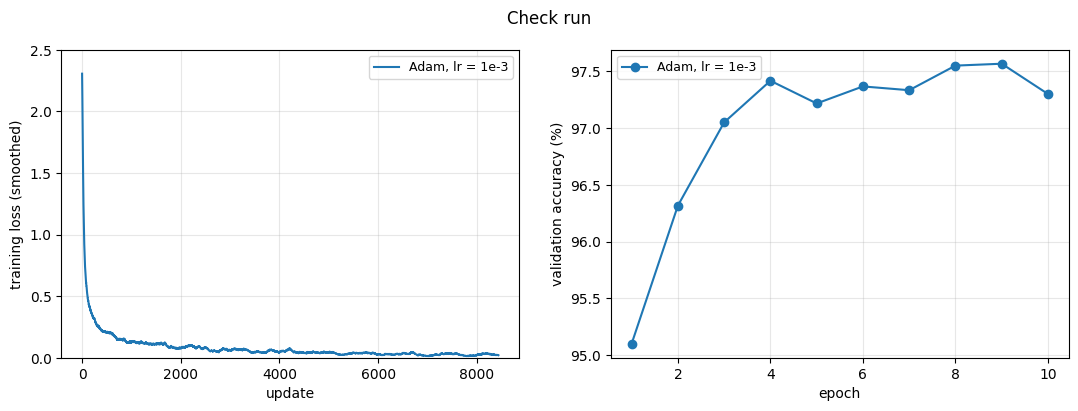

In [12]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 0.3066 | val loss 0.1589 | val acc 95.05% | 0.3 s
epoch  2 | lr 1.00e-01 | train loss 0.1170 | val loss 0.1095 | val acc 96.73% | 0.6 s
epoch  3 | lr 1.00e-01 | train loss 0.0816 | val loss 0.0952 | val acc 97.05% | 1.0 s
epoch  4 | lr 1.00e-01 | train loss 0.0593 | val loss 0.0925 | val acc 97.08% | 1.3 s
epoch  5 | lr 1.00e-01 | train loss 0.0467 | val loss 0.0912 | val acc 97.20% | 1.6 s
epoch  6 | lr 1.00e-01 | train loss 0.0358 | val loss 0.0899 | val acc 97.55% | 1.9 s
epoch  7 | lr 1.00e-01 | train loss 0.0275 | val loss 0.0775 | val acc 97.85% | 2.3 s
epoch  8 | lr 1.00e-01 | train loss 0.0213 | val loss 0.0843 | val acc 97.68% | 2.6 s
epoch  9 | lr 1.00e-01 | train loss 0.0170 | val loss 0.0967 | val acc 97.33% | 2.9 s
epoch 10 | lr 1.00e-01 | train loss 0.0117 | val loss 0.0809 | val acc 97.83% | 3.3 s


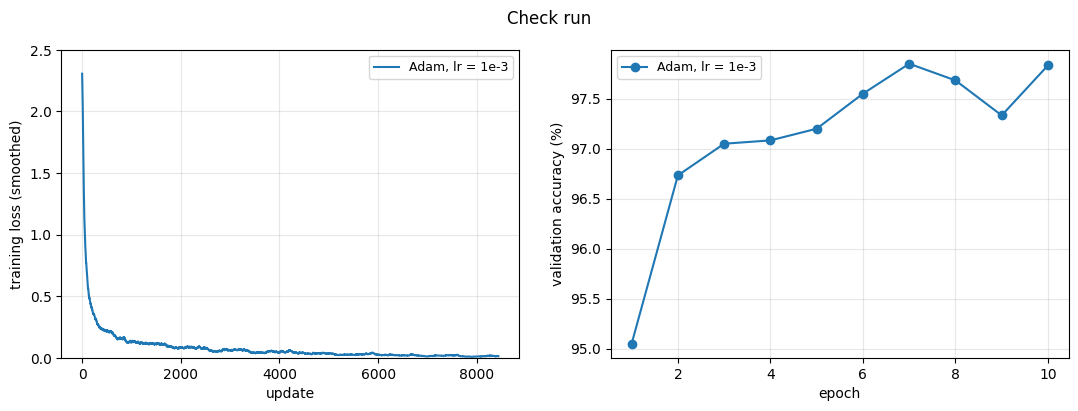

In [13]:
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 262.2302 | val loss 2.3945 | val acc 12.73% | 0.5 s
epoch  2 | lr 1.00e-01 | train loss 3.3161 | val loss 2.3178 | val acc 9.62% | 1.0 s
epoch  3 | lr 1.00e-01 | train loss 2.5777 | val loss 2.3137 | val acc 11.10% | 1.5 s
epoch  4 | lr 1.00e-01 | train loss 2.3119 | val loss 2.3149 | val acc 9.62% | 1.9 s
epoch  5 | lr 1.00e-01 | train loss 2.3115 | val loss 2.3150 | val acc 9.58% | 2.3 s
epoch  6 | lr 1.00e-01 | train loss 2.3106 | val loss 2.3087 | val acc 11.10% | 2.7 s
epoch  7 | lr 1.00e-01 | train loss 2.3107 | val loss 2.3145 | val acc 11.10% | 3.2 s
epoch  8 | lr 1.00e-01 | train loss 2.3113 | val loss 2.3085 | val acc 9.70% | 3.6 s
epoch  9 | lr 1.00e-01 | train loss 2.3110 | val loss 2.3072 | val acc 10.37% | 4.0 s
epoch 10 | lr 1.00e-01 | train loss 2.3109 | val loss 2.3110 | val acc 9.95% | 4.4 s


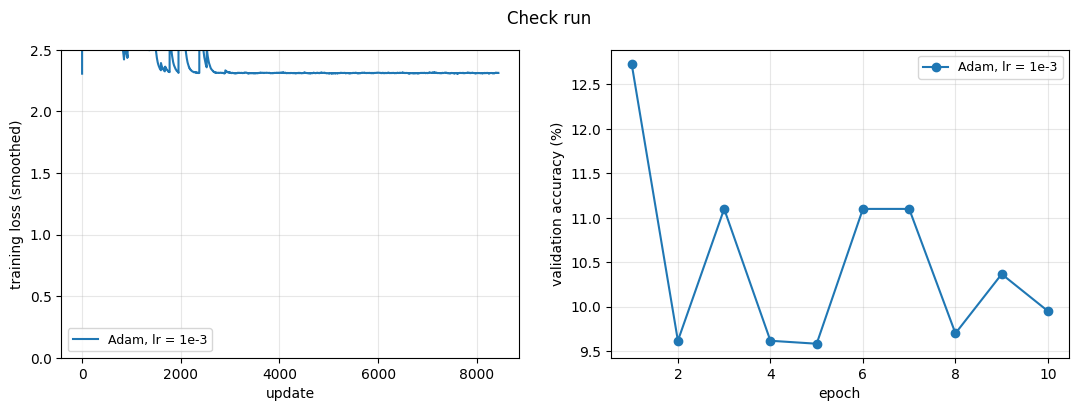

In [14]:
model = make_model(seed=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.

---
### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.



Training with learning rate = 1
epoch  1 | lr 1.00e+00 | train loss 2.3786 | val loss 2.1807 | val acc 19.35% | 0.1 s
epoch  2 | lr 1.00e+00 | train loss 2.1418 | val loss 2.0651 | val acc 21.93% | 0.2 s
epoch  3 | lr 1.00e+00 | train loss 2.0035 | val loss 8.1499 | val acc 19.47% | 0.2 s
epoch  4 | lr 1.00e+00 | train loss 2.2334 | val loss 2.1642 | val acc 18.20% | 0.3 s
epoch  5 | lr 1.00e+00 | train loss 2.3310 | val loss 2.3165 | val acc 12.60% | 0.3 s

Training with learning rate = 0.3
epoch  1 | lr 3.00e-01 | train loss 0.6903 | val loss 0.3706 | val acc 87.95% | 0.1 s
epoch  2 | lr 3.00e-01 | train loss 0.2309 | val loss 0.2696 | val acc 92.02% | 0.1 s
epoch  3 | lr 3.00e-01 | train loss 0.1443 | val loss 0.1989 | val acc 94.50% | 0.2 s
epoch  4 | lr 3.00e-01 | train loss 0.1038 | val loss 0.6692 | val acc 84.52% | 0.2 s
epoch  5 | lr 3.00e-01 | train loss 0.0950 | val loss 0.2459 | val acc 93.12% | 0.3 s

Training with learning rate = 0.1
epoch  1 | lr 1.00e-01 | train loss 0

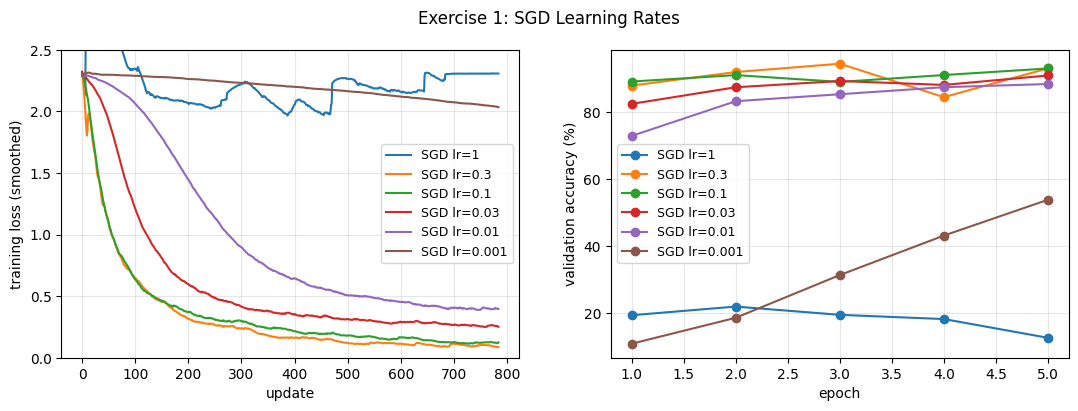


Best Validation Accuracy
----------------------------------------
Learning rate 1     : 21.93%
Learning rate 0.3   : 94.50%
Learning rate 0.1   : 93.08%
Learning rate 0.03  : 90.98%
Learning rate 0.01  : 88.43%
Learning rate 0.001 : 53.85%


In [15]:
# Exercise 1: The learning rate of SGD

learning_rates = [1, 0.3, 0.1, 0.03, 0.01, 0.001]
histories = {}

# Use the first 10,000 training examples
loader = make_loader(batch_size=64, n_train=10_000)

# Train the model with each learning rate
for lr in learning_rates:
    print(f"\nTraining with learning rate = {lr}")

    # Start from the same weights
    model = make_model(seed=0)

    # SGD optimizer without momentum
    optimizer = optim.SGD(model.parameters(), lr=lr)

    # Train for 5 epochs
    hist = fit(model, optimizer, loader, epochs=5)

    # Store the training history
    histories[f"SGD lr={lr}"] = hist

# Plot all six runs on one figure
plot_history(histories, "Exercise 1: SGD Learning Rates")

# Print the best validation accuracy
print("\nBest Validation Accuracy")
print("-" * 40)

for lr in learning_rates:
    hist = histories[f"SGD lr={lr}"]
    best_acc = max(hist["val_acc"])

    status = " (diverged)" if hist["diverged"] else ""
    print(f"Learning rate {lr:<6}: {best_acc:.2f}%{status}")



### Explanation

**Observations:**

- **Learning rate = 1:** A very large learning rate can cause unstable training because the model takes excessively large steps.
- **Learning rate = 0.3:** Training may fluctuate or diverge due to the large parameter updates.
- **Learning rate = 0.1:** The model can learn quickly, but training may still show some fluctuations.
- **Learning rate = 0.03:** Provides a balance between learning speed and stability.
- **Learning rate = 0.01:** Training is generally stable, with gradual improvements in validation accuracy.
- **Learning rate = 0.001:** Training progresses slowly because the parameter updates are very small.

**Explanation:**

The learning rate controls the step size used by Stochastic Gradient Descent (SGD) to update the model parameters.

The update rule is:

$$
\theta_{t+1} = \theta_t - \alpha \nabla J(\theta_t)
$$

where:
- $\theta$ represents the model parameters.
- $\alpha$ is the learning rate.
- $\nabla J(\theta)$ is the gradient of the loss function.

A large learning rate may cause the optimizer to overshoot the minimum, resulting in unstable training or divergence. A small learning rate produces more stable updates but requires more iterations to converge.

**Conclusion:**

The learning rate significantly affects the convergence speed, training stability, and validation accuracy of SGD. The best learning rate should be selected based on the highest validation accuracy achieved during the experiments, rather than assuming that a larger or smaller learning rate is always better.

---

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


Learning Rate = 0.01

Training with batch size = 1
epoch  1 | lr 1.00e-02 | train loss 0.4416 | val loss 0.4109 | val acc 89.62% | 1.9 s
epoch  2 | lr 1.00e-02 | train loss 0.2115 | val loss 0.2225 | val acc 93.57% | 3.7 s
epoch  3 | lr 1.00e-02 | train loss 0.1411 | val loss 0.2424 | val acc 93.20% | 5.5 s
Updates per epoch: 10000
Average time per epoch: 1.83 seconds
Best validation accuracy: 93.57%
Diverged: False

Training with batch size = 32
epoch  1 | lr 1.00e-02 | train loss 1.4694 | val loss 0.6934 | val acc 83.52% | 0.1 s
epoch  2 | lr 1.00e-02 | train loss 0.5182 | val loss 0.4488 | val acc 86.75% | 0.2 s
epoch  3 | lr 1.00e-02 | train loss 0.3849 | val loss 0.3840 | val acc 88.87% | 0.3 s
Updates per epoch: 313
Average time per epoch: 0.09 seconds
Best validation accuracy: 88.87%
Diverged: False

Training with batch size = 256
epoch  1 | lr 1.00e-02 | train loss 2.2508 | val loss 2.1822 | val acc 25.18% | 0.0 s
epoch  2 | lr 1.00e-02 | train loss 2.1034 | val loss 2.0016 | 

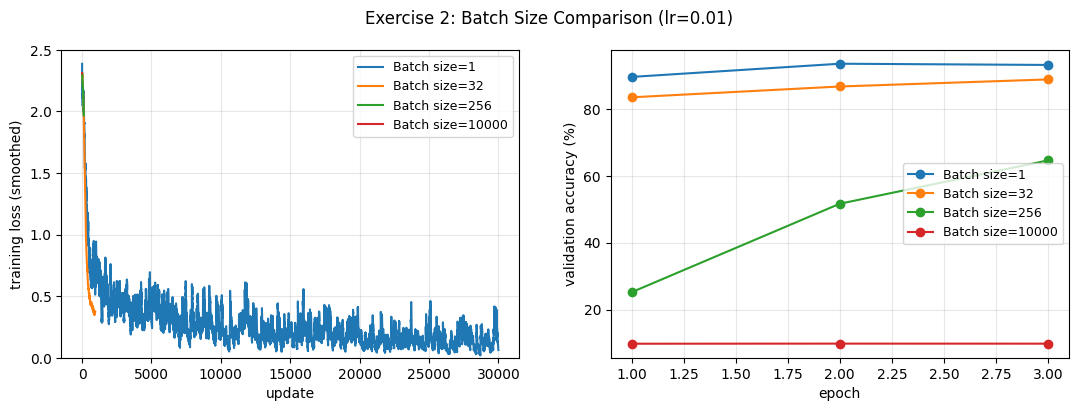


Learning Rate = 0.1

Training with batch size = 1
epoch  1 | lr 1.00e-01 | train loss nan | val loss nan | val acc 9.72% | 0.5 s
diverged (loss is nan or inf): stopping
Updates per epoch: 10000
Average time per epoch: 0.48 seconds
Best validation accuracy: 9.72%
Diverged: True

Training with batch size = 32
epoch  1 | lr 1.00e-01 | train loss 0.5535 | val loss 0.3337 | val acc 89.72% | 0.1 s
epoch  2 | lr 1.00e-01 | train loss 0.2262 | val loss 0.2587 | val acc 91.73% | 0.2 s
epoch  3 | lr 1.00e-01 | train loss 0.1440 | val loss 0.2135 | val acc 93.57% | 0.3 s
Updates per epoch: 313
Average time per epoch: 0.09 seconds
Best validation accuracy: 93.57%
Diverged: False

Training with batch size = 256
epoch  1 | lr 1.00e-01 | train loss 1.3641 | val loss 0.8302 | val acc 72.15% | 0.0 s
epoch  2 | lr 1.00e-01 | train loss 0.5005 | val loss 0.9585 | val acc 67.50% | 0.1 s
epoch  3 | lr 1.00e-01 | train loss 0.3926 | val loss 0.7760 | val acc 74.68% | 0.1 s
Updates per epoch: 40
Average tim

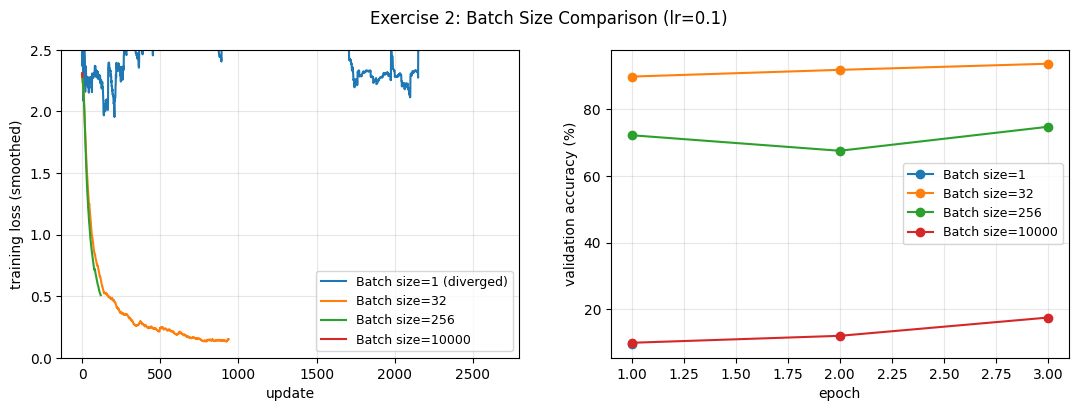

In [24]:
# Exercise 2: Comparing batch sizes with SGD

batch_sizes = [1, 32, 256, 10_000]
learning_rates = [0.01, 0.1]

for lr in learning_rates:
    print(f"\n{'=' * 60}")
    print(f"Learning Rate = {lr}")
    print(f"{'=' * 60}")

    histories = {}

    for batch_size in batch_sizes:
        print(f"\nTraining with batch size = {batch_size}")

        # Use the first 10,000 training examples
        loader = make_loader(
            batch_size=batch_size,
            n_train=10_000
        )

        # Create model with the same initial weights
        model = make_model(seed=0)

        # SGD without momentum
        optimizer = optim.SGD(
            model.parameters(),
            lr=lr
        )

        # Train for 3 epochs
        hist = fit(
            model,
            optimizer,
            loader,
            epochs=3
        )

        histories[f"Batch size={batch_size}"] = hist

        # Number of updates per epoch
        updates = len(loader)

        # Time per epoch (hist["time"] is cumulative)
        epoch_times = [
            hist["time"][0]
        ] + [
            hist["time"][i] - hist["time"][i - 1]
            for i in range(1, len(hist["time"]))
        ]

        avg_time = sum(epoch_times) / len(epoch_times)

        # Best validation accuracy
        valid_accs = [
            acc for acc in hist["val_acc"]
            if math.isfinite(acc)
        ]
        best_acc = max(valid_accs) if valid_accs else float("nan")

        print(f"Updates per epoch: {updates}")
        print(f"Average time per epoch: {avg_time:.2f} seconds")
        print(f"Best validation accuracy: {best_acc:.2f}%")
        print(f"Diverged: {hist['diverged']}")

    # Plot all four runs for this learning rate
    plot_history(
        histories,
        title=f"Exercise 2: Batch Size Comparison (lr={lr})"
    )


### Explanation 

**Observations:**

We trained SGD models using batch sizes of 1, 32, 256, and 10,000 for 3 epochs with two learning rates: 0.01 and 0.1.

- **Batch size = 1:** Performs 10,000 updates per epoch. The gradient is noisy because each update uses only one example. Training can also be slow due to the large number of updates.
- **Batch size = 32:** Performs 313 updates per epoch. It provides a balance between frequent updates and efficient computation.
- **Batch size = 256:** Performs 40 updates per epoch. It benefits from vectorized computation and usually produces smoother gradient estimates.
- **Batch size = 10,000:** Performs only 1 update per epoch. The gradient is computed using the entire training set, but the model receives only 3 parameter updates over the experiment.

**Explanation:**

The batch size determines how many training examples are used to calculate the gradient before updating the model parameters.

The number of updates per epoch is:

$$
\text{Updates per epoch} =
\left\lceil \frac{N}{B} \right\rceil
$$

where:
- $N = 10,000$ is the number of training examples.
- $B$ is the batch size.

A small batch size produces frequent updates with more gradient noise, while a large batch size produces fewer updates with more accurate gradient estimates.

Increasing the learning rate from 0.01 to 0.1 increases the size of each parameter update. This may accelerate learning but can also make training less stable, particularly with small batch sizes.

**Conclusion:**

Batch size affects the number of parameter updates, computational efficiency, training stability, and validation accuracy.

Mini-batch gradient descent provides a practical balance between stochastic gradient descent and full-batch gradient descent. The best combination of batch size and learning rate should be determined by comparing the measured validation accuracies and training times.

---


### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.


Training: Plain SGD (lr=0.01)
epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.1 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 0.1 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 0.2 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 0.3 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 0.3 s

Training: Momentum 0.9 (lr=0.01)
epoch  1 | lr 1.00e-02 | train loss 0.8192 | val loss 0.3558 | val acc 89.52% | 0.1 s
epoch  2 | lr 1.00e-02 | train loss 0.2942 | val loss 0.2736 | val acc 91.87% | 0.1 s
epoch  3 | lr 1.00e-02 | train loss 0.2074 | val loss 0.2625 | val acc 91.73% | 0.2 s
epoch  4 | lr 1.00e-02 | train loss 0.1585 | val loss 0.2152 | val acc 93.52% | 0.3 s
epoch  5 | lr 1.00e-02 | train loss 0.1236 | val loss 0.1914 | val acc 94.28% | 0.3 s

Training: Nesterov 0.9 (lr=0.01)
epoch  1 | lr 1.00e-02 | train loss 0.775

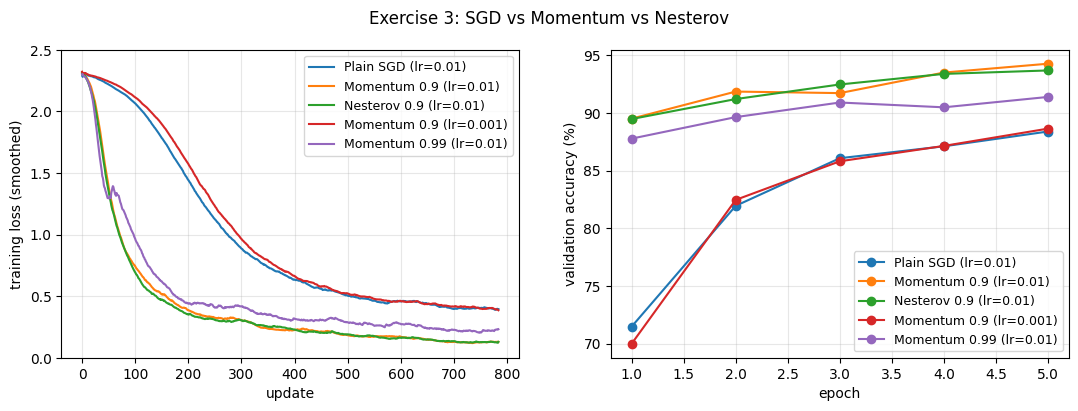


Best Validation Accuracy
-----------------------------------------------------------------
Plain SGD (lr=0.01)                : 88.40%
Momentum 0.9 (lr=0.01)             : 94.28%
Nesterov 0.9 (lr=0.01)             : 93.70%
Momentum 0.9 (lr=0.001)            : 88.65%
Momentum 0.99 (lr=0.01)            : 91.40%


In [25]:

# Exercise 3: Momentum

# Batch size = 64, first 10,000 examples
loader = make_loader(batch_size=64, n_train=10_000)

# Five SGD configurations
configs = {
    "Plain SGD (lr=0.01)": {
        "lr": 0.01
    },
    "Momentum 0.9 (lr=0.01)": {
        "lr": 0.01,
        "momentum": 0.9
    },
    "Nesterov 0.9 (lr=0.01)": {
        "lr": 0.01,
        "momentum": 0.9,
        "nesterov": True
    },
    "Momentum 0.9 (lr=0.001)": {
        "lr": 0.001,
        "momentum": 0.9
    },
    "Momentum 0.99 (lr=0.01)": {
        "lr": 0.01,
        "momentum": 0.99
    }
}

histories = {}

# Train all five models
for name, params in configs.items():
    print(f"\n{'=' * 55}")
    print(f"Training: {name}")
    print(f"{'=' * 55}")

    # Same initial weights for every model
    model = make_model(seed=0)

    # Create SGD optimizer
    optimizer = optim.SGD(
        model.parameters(),
        **params
    )

    # Train for 5 epochs
    hist = fit(
        model,
        optimizer,
        loader,
        epochs=5
    )

    histories[name] = hist

# Plot all five runs on one figure
plot_history(
    histories,
    title="Exercise 3: SGD vs Momentum vs Nesterov"
)

# Print best validation accuracy
print("\nBest Validation Accuracy")
print("-" * 65)

for name, hist in histories.items():
    valid_accs = [
        acc for acc in hist["val_acc"]
        if math.isfinite(acc)
    ]

    best_acc = max(valid_accs) if valid_accs else float("nan")
    status = " (diverged)" if hist["diverged"] else ""

    print(f"{name:<35}: {best_acc:.2f}%{status}")



### Explanation

**Observations:**

We compared five SGD configurations using a batch size of 64 and 5 training epochs.

- **Plain SGD (lr=0.01):** Serves as the baseline. It updates the weights using only the current gradient.
- **Momentum = 0.9 (lr=0.01):** Momentum can accelerate convergence by accumulating previous gradient directions and reducing oscillations.
- **Nesterov Momentum = 0.9 (lr=0.01):** Uses a look-ahead gradient to anticipate the next parameter position, potentially improving convergence.
- **Momentum = 0.9 (lr=0.001):** A smaller learning rate reduces the step size. Momentum can compensate for some of the slower progress.
- **Momentum = 0.99 (lr=0.01):** Strong momentum retains more information from previous gradients but may produce overshooting or unstable training.

**Explanation:**

Momentum improves standard SGD by accumulating gradients across successive updates.

The momentum equations are:

$$
v_t = \beta v_{t-1} + \nabla J(\theta_t)
$$

$$
\theta_{t+1} = \theta_t - \alpha v_t
$$

where:
- $\alpha$ is the learning rate.
- $\beta$ is the momentum coefficient.
- $v_t$ is the accumulated gradient.
- $\nabla J(\theta_t)$ is the current gradient.

With momentum, the optimizer can move faster in consistent gradient directions and reduce oscillations in directions where gradients frequently change sign.

Nesterov momentum differs by computing the gradient at a look-ahead position, which can help the optimizer correct its direction earlier.

A very high momentum value such as 0.99 can accelerate training, but it can also increase the risk of overshooting the minimum.

**Conclusion:**

Momentum can improve SGD convergence by using information from previous gradients. However, its effectiveness depends on the combination of learning rate and momentum coefficient.

The best optimizer should be selected by comparing validation accuracy, convergence speed, and training stability rather than assuming that higher momentum is always better.

---


### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

In [18]:
# Exercise 4

**Exercise 4: your observations and explanation.** *Write here.*

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

In [19]:
# Exercise 5

**Exercise 5: your observations and explanation.** *Write here.*

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

In [20]:
# Exercise 6

**Exercise 6: your observations and explanation.** *Write here.*

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

In [21]:
# Exercise 7

**Exercise 7: your observations and explanation.** *Write here.*

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [22]:
# Exercise 8

**Exercise 8: your observations and explanation.** *Write here.*

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

In [23]:
# Exercise 9 (optional)

**Exercise 9: your observations and explanation.** *Write here.*